# Env Tests with SharpZ

We now have a backend which supports all the tools we need for sharpZ:
- Resoultion/Level changing
- Indentifying clusters at levels
- Changing nodes at levels based on node selection
- Calculating Energy and Trace at those chalenges
- Accepet/Rejection based on minimum delta E threshold and random temperature scaling acceptance

Now we have an environment which is what the agent uses to interact with the som. We want to test the following:

1. Setting up the env easily
2. Obtaining a reasonable state from the env
3. Viewing the full env easily
4. Making actions + measuring change

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle
from som_rl.som.som_backend import SharpZBackendConfig, SharpZSOMBackend
from som_rl.env.env import (EnergyFloorSchedule, SOMEnergyEnvConfig, 
                SOMEnergyBaseEnv, EnvTeleportNodeRandomBin, EnvTeleportXYRandomBin, EnvCursorLocalRandomBin, 
                EnvNodeAndLevelRandomBin, EnvNodeAndBin, EnvNodeLevelBin)

DATA = "data"
H, W = 200, 200
K = 11

In [2]:
DATA = "data"  # adjust

npz = np.load(f"{DATA}/correlations_dl/npairs_compact.npz")
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

node_indices_photo = np.load(f"{DATA}/node_indices_fc.npy")  # (Nphot,)
initial_node_bins  = np.load(f"{DATA}/nodes_labels_initial_fc_200_ext.npy")  # (40000,)
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy")  # (Nref,) in [0..10]

weighted_clusters  = np.load(f"{DATA}/weighted_clusters_5c_1t200.npy")  # (L,40000)

# umatrix: if you already extracted it from the pickled somoclu object, load it.
# If not, set to None for now.
umatrix = None  # np.load(f"{DATA}/umatrix.npy")  # (200,200)

cfg_b = SharpZBackendConfig(
    grid_shape=(200,200),
    num_bins=11,
    objective_mode="energy",
    T_max=1.0,
    T_min=0.01,
    n_steps=50000,
    level_min=0,
    level_max=200,
    min_abs_deltaE=1e-5,
)

som = SharpZSOMBackend(
    cfg=cfg_b,
    dd=dd, dr=dr, rd=rd, rr=rr,
    node_indices_photo=node_indices_photo,
    initial_node_bins=initial_node_bins,
    reference_labels=reference_labels,
    umatrix=umatrix,
    weighted_clusters=weighted_clusters,
)

print("Backend ready.")
print("E0:", som.energy_E(), "trace:", som.trace_xi())
print("levels:", som.levels_available())


Setting weighted_clusters for SharpZ backend...
Backend ready.
E0: 0.023775093565945846 trace: 0.2785188710136125
levels: 201


In [3]:
lvl = 30
node = 12345
cid = som.cluster_id_for_node(node, lvl)
nodes = som.nodes_for_cluster_id(lvl, cid)
print("cid", cid, "nodes.size", nodes.size, "contains node?", node in set(nodes.tolist()))


cid 808 nodes.size 58 contains node? True


In [4]:
H, W = 200, 200
N = H * W

print("current_bins:", som.current_bins.shape, som.current_bins.min(), som.current_bins.max())
print("node_gal_counts nonzero nodes:", int((som.node_gal_counts > 0).sum()))

rng = np.random.default_rng(0)
nonempty = np.flatnonzero(som.node_gal_counts > 0)
node = int(rng.choice(nonempty))
x, y = som.index_to_xy(node)
print("sample node:", node, "xy:", (x, y))

def cluster_nodes_at_level(som, lvl: int, cid: int) -> np.ndarray:
    order = som._cluster_order[lvl]
    offsets = som._cluster_offsets[lvl]
    a = int(offsets[cid])
    b = int(offsets[cid + 1])
    return order[a:b]

for lvl in [0, 30, 100, 200]:
    if lvl >= som.levels_available():
        continue
    cid = int(som.weighted_clusters[lvl, node])
    nodes = cluster_nodes_at_level(som, lvl, cid)
    nonempty_ct = int((som.node_gal_counts[nodes] > 0).sum())
    print(f"level {lvl:3d} cluster {cid:5d} size={nodes.size} nonempty={nonempty_ct}")


current_bins: (40000,) 0 10
node_gal_counts nonzero nodes: 40000
sample node: 34024 xy: (24, 170)
level   0 cluster     0 size=40000 nonempty=40000
level  30 cluster   636 size=34 nonempty=34
level 100 cluster  6349 size=6 nonempty=6
level 200 cluster 16823 size=1 nonempty=1


In [5]:
cfg_e = SOMEnergyEnvConfig(
    obs_mode="global",              # try "global" later
    patch_size=9,
    include_umatrix=(som.umatrix is not None),
    include_cluster_features=True,
    include_empty_mask=True,
    include_visit_count=True,
    include_recent_mask=False,     # turn on later if you want
    max_steps=50000,
    initial_level=100,
    allowed_levels=(30, 50, 80, 100, 150),
    accept_rule="sa",              # "sa" matches SharpZ style; "positive_only" is your strict baseline
    reward_type="deltaE",
    step_penalty=0.0,
    energy_floor = EnergyFloorSchedule(
        default=1e-5)
)

env_node = EnvTeleportNodeRandomBin(som, cfg_e)
env_xy   = EnvTeleportXYRandomBin(som, cfg_e)
env_loc  = EnvCursorLocalRandomBin(som, cfg_e)
env_nl   = EnvNodeAndLevelRandomBin(som, cfg_e)
env_nb   = EnvNodeAndBin(som, cfg_e)
env_nlb  = EnvNodeLevelBin(som, cfg_e)

print("Envs ready:", [type(e).__name__ for e in [env_node, env_xy, env_loc, env_nl, env_nb, env_nlb]])


Envs ready: ['EnvTeleportNodeRandomBin', 'EnvTeleportXYRandomBin', 'EnvCursorLocalRandomBin', 'EnvNodeAndLevelRandomBin', 'EnvNodeAndBin', 'EnvNodeLevelBin']


In [6]:
obs, info = env_node.reset(seed=0)
print("reset info:", info)
print("obs keys:", obs.keys())
for k,v in obs.items():
    if isinstance(v, np.ndarray):
        print(k, v.shape, v.dtype, "min/max:", v.min(), v.max())
    else:
        print(k, type(v))


reset info: {'energy': 0.023775093565945846, 'level': 100, 'temperature': 1.0}
obs keys: dict_keys(['bins', 'cursor', 'empty', 'cluster_boundary', 'cluster_size', 'visit_count', 'scalars'])
bins (200, 200) int16 min/max: 0 10
cursor (2,) int32 min/max: 127 170
empty (200, 200) uint8 min/max: 0 0
cluster_boundary (200, 200) uint8 min/max: 0 1
cluster_size (200, 200) float32 min/max: 0.016393442 1.0
visit_count (200, 200) float32 min/max: 0.0 0.0
scalars (4,) float32 min/max: 0.023775093 1.0


In [7]:
def one_step(env, action):
    obs0, info0 = env.reset(seed=0)
    E0 = float(info0["energy"])
    obs1, r, term, trunc, info1 = env.step(action)
    return E0, r, term, trunc, info1, obs1

H, W = 200, 200
node = 12345
xy = (node % W, node // W)

# node action
E0, r, term, trunc, info1, _ = one_step(env_node, node)
print("EnvTeleportNodeRandomBin:", "E0", E0, "r", r, "accepted", info1["accepted"], "dE", info1["dE"], "lvl", info1["level"])

# xy action
E0, r, term, trunc, info1, _ = one_step(env_xy, np.array(xy))
print("EnvTeleportXYRandomBin:", "E0", E0, "r", r, "accepted", info1["accepted"], "dE", info1["dE"], "lvl", info1["level"])

# local action (center cell)
center = (env_loc.ps * env_loc.ps) // 2
E0, r, term, trunc, info1, _ = one_step(env_loc, center)
print("EnvCursorLocalRandomBin:", "E0", E0, "r", r, "accepted", info1["accepted"], "dE", info1["dE"], "lvl", info1["level"])

# node+level action
E0, r, term, trunc, info1, _ = one_step(env_nl, np.array([node, 3]))  # allowed_levels[3]
print("EnvNodeAndLevelRandomBin:", "E0", E0, "r", r, "accepted", info1["accepted"], "dE", info1["dE"], "lvl", info1["level"])

# node+bin action (force bin=0)
E0, r, term, trunc, info1, _ = one_step(env_nb, np.array([node, 0]))
print("EnvNodeAndBin:", "E0", E0, "r", r, "accepted", info1["accepted"], "dE", info1["dE"], "lvl", info1["level"])

# node+level+bin action
E0, r, term, trunc, info1, _ = one_step(env_nlb, np.array([node, 4, 10]))
print("EnvNodeLevelBin:", "E0", E0, "r", r, "accepted", info1["accepted"], "dE", info1["dE"], "lvl", info1["level"])


EnvTeleportNodeRandomBin: E0 0.023775093565945846 r -2.291608377186921e-06 accepted False dE -2.291608377186921e-06 lvl 100
EnvTeleportXYRandomBin: E0 0.023775093565945846 r -2.291608377186921e-06 accepted False dE -2.291608377186921e-06 lvl 100
EnvCursorLocalRandomBin: E0 0.023775093565945846 r -5.775718275972952e-07 accepted False dE -5.775718275972952e-07 lvl 100
EnvNodeAndLevelRandomBin: E0 0.023775093565945846 r -2.291608377186921e-06 accepted False dE -2.291608377186921e-06 lvl 100
EnvNodeAndBin: E0 0.023775093565945846 r -7.502260316490095e-06 accepted False dE -7.502260316490095e-06 lvl 100
EnvNodeLevelBin: E0 0.023775093565945846 r -2.399431949559605e-06 accepted False dE -2.399431949559605e-06 lvl 150


In [8]:
# ensure both envs target the same node and behave coherently
env_node.reset(seed=1)
env_xy.reset(seed=1)

node = 22222
xy = (node % W, node // W)

# step once on each (note: backend state is shared, so do one env at a time with reset_to_initial)
som.reset_to_initial()
obs, info = env_node.reset(seed=1)
_, r1, _, _, i1 = env_node.step(node)

som.reset_to_initial()
obs, info = env_xy.reset(seed=1)
_, r2, _, _, i2 = env_xy.step(np.array(xy))

print("node env:", i1["accepted"], i1["dE"], "lvl", i1["level"])
print("xy env:  ", i2["accepted"], i2["dE"], "lvl", i2["level"])


node env: False -0.00014977124655404794 lvl 100
xy env:   False -0.00014977124655404794 lvl 100


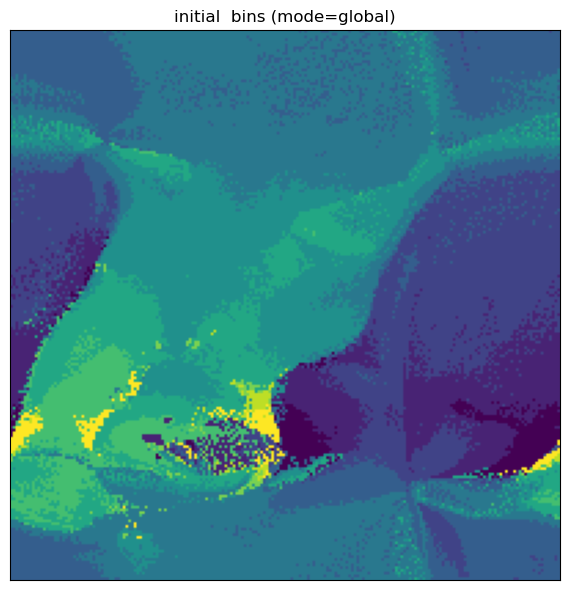

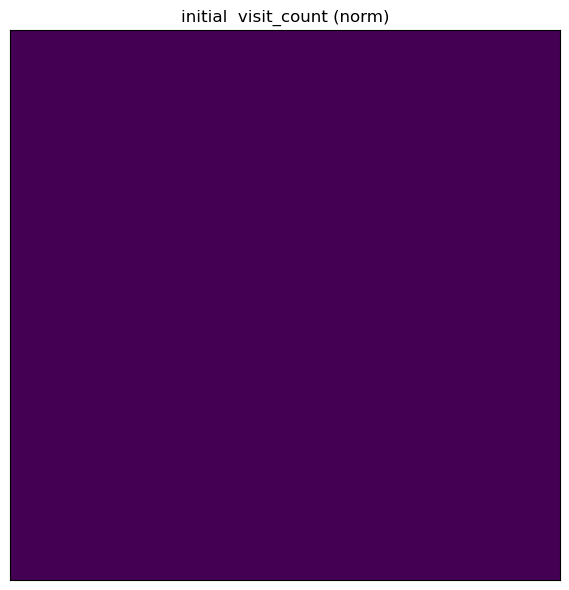

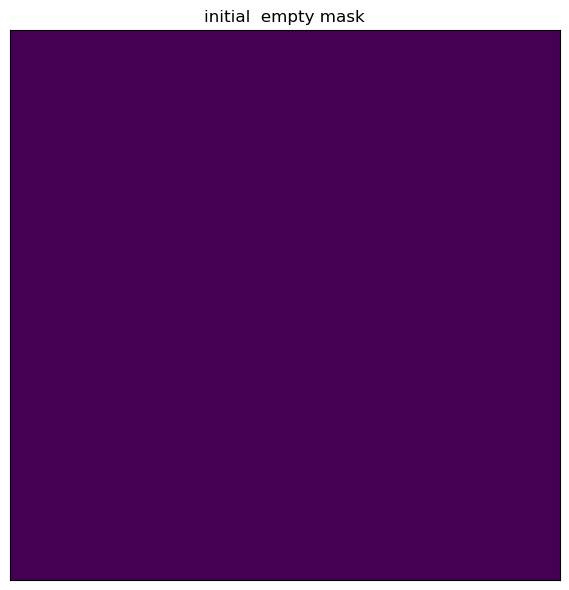

In [9]:
def plot_env_state(env, title=""):
    obs = env._obs()
    bins = obs["bins"]
    vc = obs.get("visit_count", None)
    empty = obs.get("empty", None)

    plt.figure(figsize=(6,6))
    plt.imshow(bins)
    plt.title(title + f" bins (mode={env.cfg.obs_mode})")
    plt.xticks([]); plt.yticks([])
    plt.tight_layout()
    plt.show()

    if vc is not None:
        plt.figure(figsize=(6,6))
        plt.imshow(vc)
        plt.title(title + " visit_count (norm)")
        plt.xticks([]); plt.yticks([])
        plt.tight_layout()
        plt.show()

    if empty is not None:
        plt.figure(figsize=(6,6))
        plt.imshow(empty)
        plt.title(title + " empty mask")
        plt.xticks([]); plt.yticks([])
        plt.tight_layout()
        plt.show()

# example
som.reset_to_initial()
env_node.reset(seed=0)
plot_env_state(env_node, "initial ")


steps: 5000 accept_rate: 0.012 E0->Eend: 0.023775093565945846 -> 0.025883377038596143


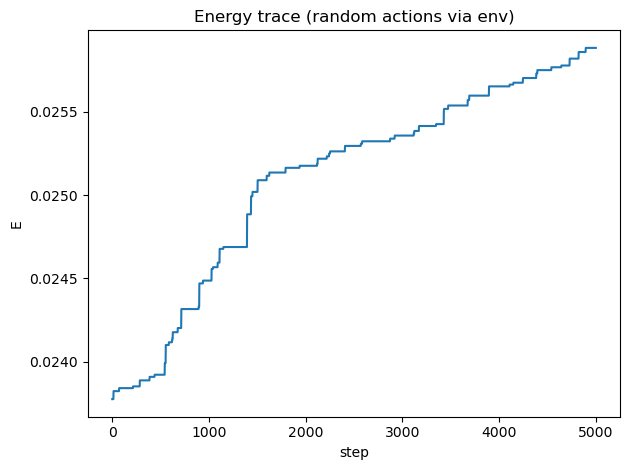

In [10]:
def rollout(env, n_steps=2000, seed=0, action_mode="random"):
    obs, info = env.reset(seed=seed)
    E = [float(info["energy"])]
    acc = 0
    dEs = []
    for t in range(n_steps):
        if action_mode == "random":
            a = env.action_space.sample()
        else:
            raise ValueError("unknown action_mode")
        obs, r, term, trunc, info = env.step(a)
        E.append(float(info["E1"]))
        acc += int(bool(info["accepted"]))
        dEs.append(float(info.get("dE", 0.0)))
        if trunc or term:
            break
    return {
        "E": np.array(E, dtype=float),
        "accepted": acc,
        "steps": len(dEs),
        "accept_rate": acc / max(1, len(dEs)),
        "dE": np.array(dEs, dtype=float),
        "final_info": info,
    }

som.reset_to_initial()
stats = rollout(env_node, n_steps=5000, seed=0)
print("steps:", stats["steps"], "accept_rate:", stats["accept_rate"], "E0->Eend:", stats["E"][0], "->", stats["E"][-1])

plt.figure()
plt.plot(stats["E"])
plt.title("Energy trace (random actions via env)")
plt.xlabel("step")
plt.ylabel("E")
plt.tight_layout()
plt.show()


SA accept_rate: 0.0116 Eend: 0.02587496426315995
POS accept_rate: 0.0078 Eend: 0.025204680971204874


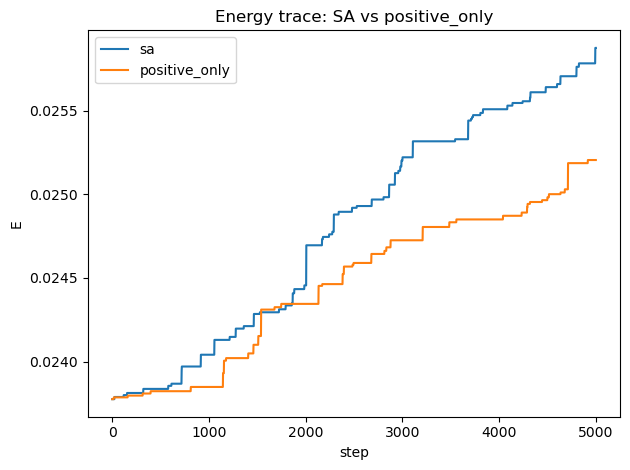

In [11]:
# clone env config with strict accept
cfg_pos = SOMEnergyEnvConfig(**{**cfg_e.__dict__, "accept_rule": "positive_only"})
env_node_pos = EnvTeleportNodeRandomBin(som, cfg_pos)

som.reset_to_initial()
sa_stats = rollout(env_node, n_steps=5000, seed=0)
som.reset_to_initial()
pos_stats = rollout(env_node_pos, n_steps=5000, seed=0)

print("SA accept_rate:", sa_stats["accept_rate"], "Eend:", sa_stats["E"][-1])
print("POS accept_rate:", pos_stats["accept_rate"], "Eend:", pos_stats["E"][-1])

plt.figure()
plt.plot(sa_stats["E"], label="sa")
plt.plot(pos_stats["E"], label="positive_only")
plt.legend()
plt.title("Energy trace: SA vs positive_only")
plt.xlabel("step")
plt.ylabel("E")
plt.tight_layout()
plt.show()


runtime (s): 26.906254053115845
steps: 50000
accept_rate: 0.0046
E0->Eend: 0.023775093565945846 -> 0.03176660018721283
mean dE (accepted only): -7.3204943537005e-05


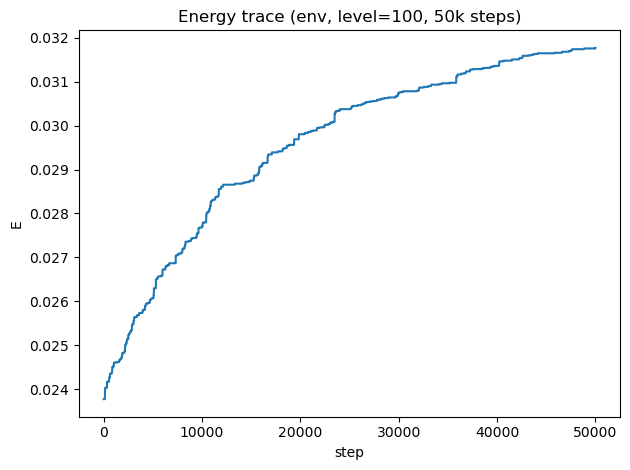

In [12]:
cfg_lvl100 = SOMEnergyEnvConfig(**{**cfg_e.__dict__, "initial_level": 100, "allowed_levels": (100,)})
env_lvl100 = EnvTeleportNodeRandomBin(som, cfg_lvl100)

som.reset_to_initial()
t0 = time.time()
stats = rollout(env_lvl100, n_steps=50_000, seed=0)
dt = time.time() - t0

print("runtime (s):", dt)
print("steps:", stats["steps"])
print("accept_rate:", stats["accept_rate"])
print("E0->Eend:", stats["E"][0], "->", stats["E"][-1])
print("mean dE (accepted only):", stats["dE"][stats["dE"]!=0].mean() if np.any(stats["dE"]!=0) else 0.0)

plt.figure()
plt.plot(stats["E"])
plt.title("Energy trace (env, level=100, 50k steps)")
plt.xlabel("step")
plt.ylabel("E")
plt.tight_layout()
plt.show()


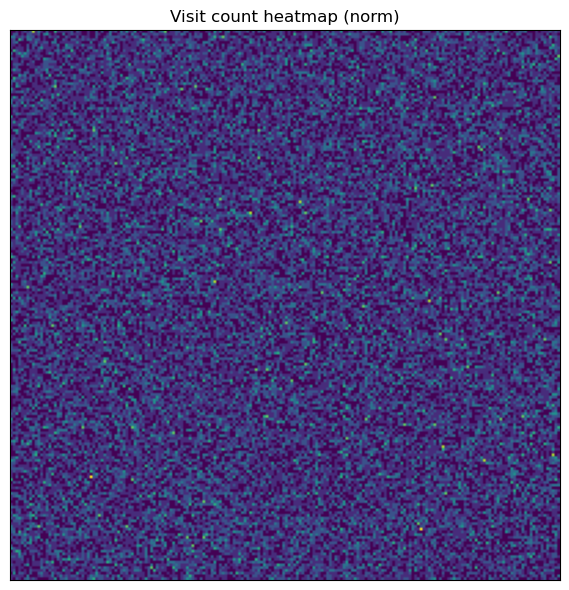

In [13]:
# After the rollout, env has visit_count populated.
vc = env_lvl100.visit_count.reshape(200,200).astype(float)
vc /= max(1.0, vc.max())

plt.figure(figsize=(6,6))
plt.imshow(vc)
plt.title("Visit count heatmap (norm)")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()


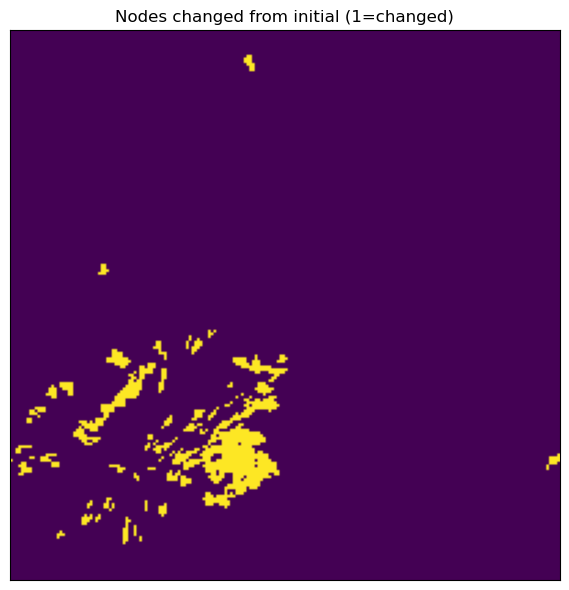

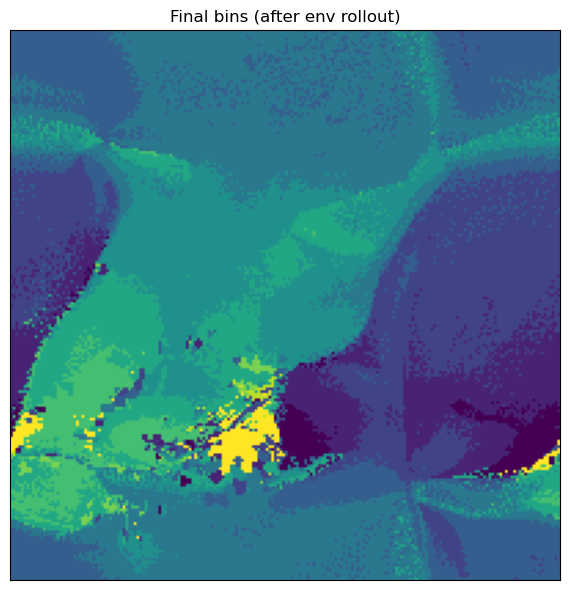

In [14]:
final_bins = som.current_bins.reshape(200,200).copy()
initial_bins_grid = np.asarray(initial_node_bins, dtype=np.int16).reshape(200,200)

diff = (final_bins != initial_bins_grid).astype(np.uint8)

plt.figure(figsize=(6,6))
plt.imshow(diff)
plt.title("Nodes changed from initial (1=changed)")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,6))
plt.imshow(final_bins)
plt.title("Final bins (after env rollout)")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()


In [15]:
from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych

In [16]:
perfect = get_perfect_bins()

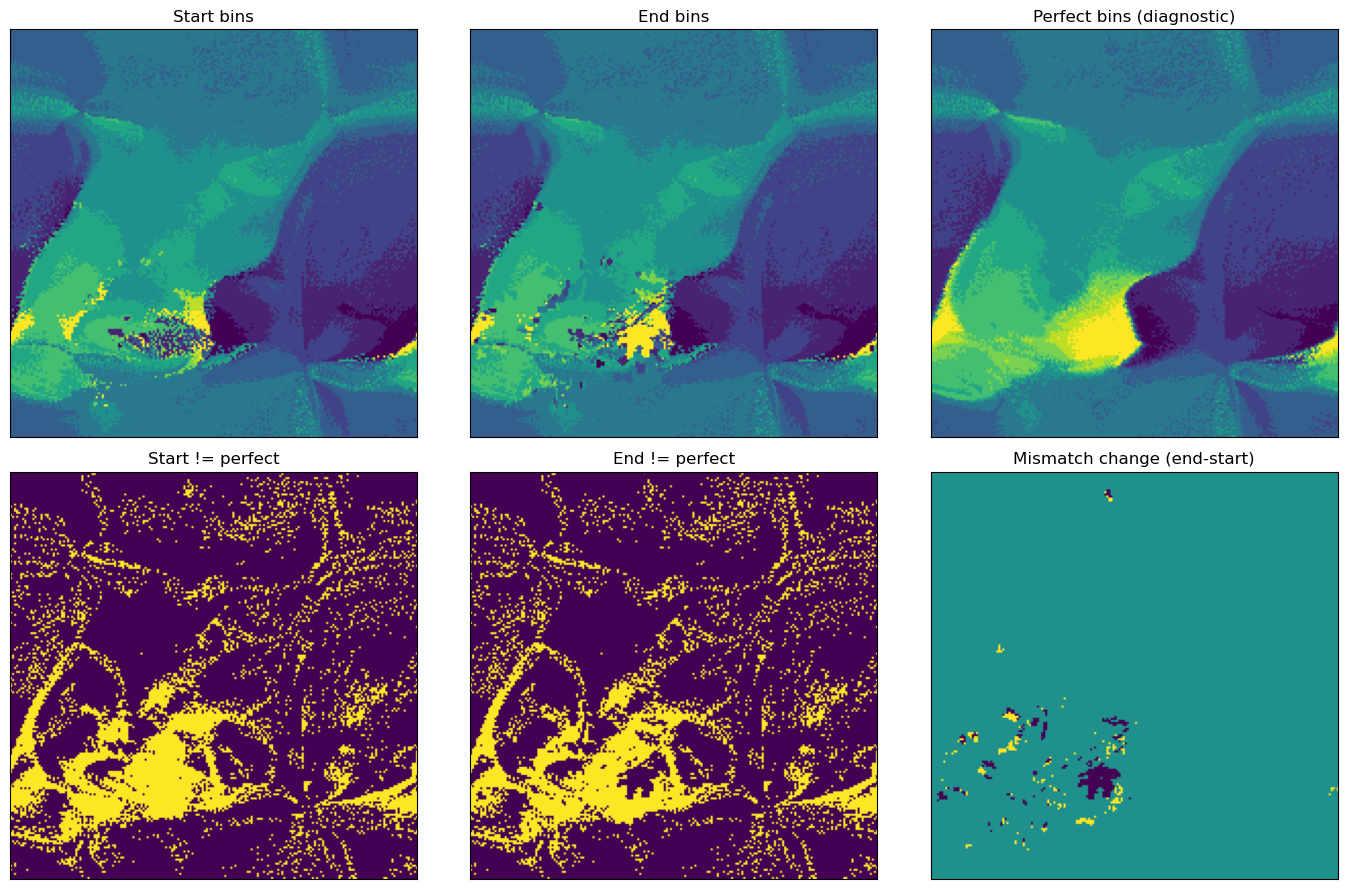

Match to perfect: start=0.795, end=0.799, Δ=+0.005


In [17]:
obs = env_lvl100._obs()
env_final_bins = obs["bins"]

plot_bins_triptych(
    perfect_bins=perfect,
    end_bins=env_final_bins,
    start_bins=initial_node_bins.reshape(som.H, som.W)
)

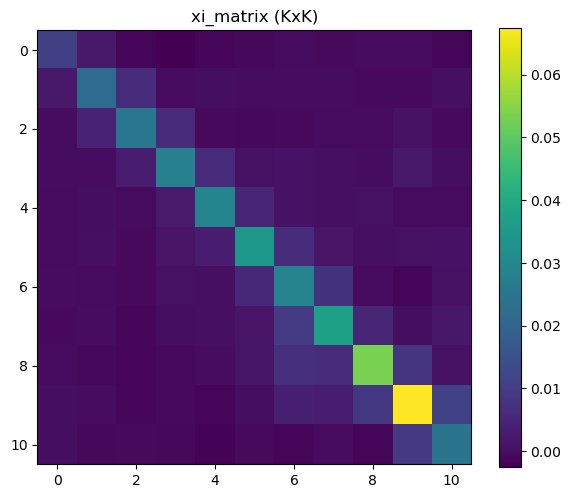

diag mean: 0.03279480808027726 off mean: 0.001028207893064434
trace: 0.36074288888304984 energy: 0.03176660018721283


In [18]:
xi = som.xi_matrix()
plt.figure(figsize=(6,5))
plt.imshow(xi)
plt.title("xi_matrix (KxK)")
plt.colorbar()
plt.tight_layout()
plt.show()

diag = np.diag(xi)
off = xi[~np.eye(K, dtype=bool)]
print("diag mean:", diag.mean(), "off mean:", off.mean())
print("trace:", som.trace_xi(), "energy:", som.energy_E())

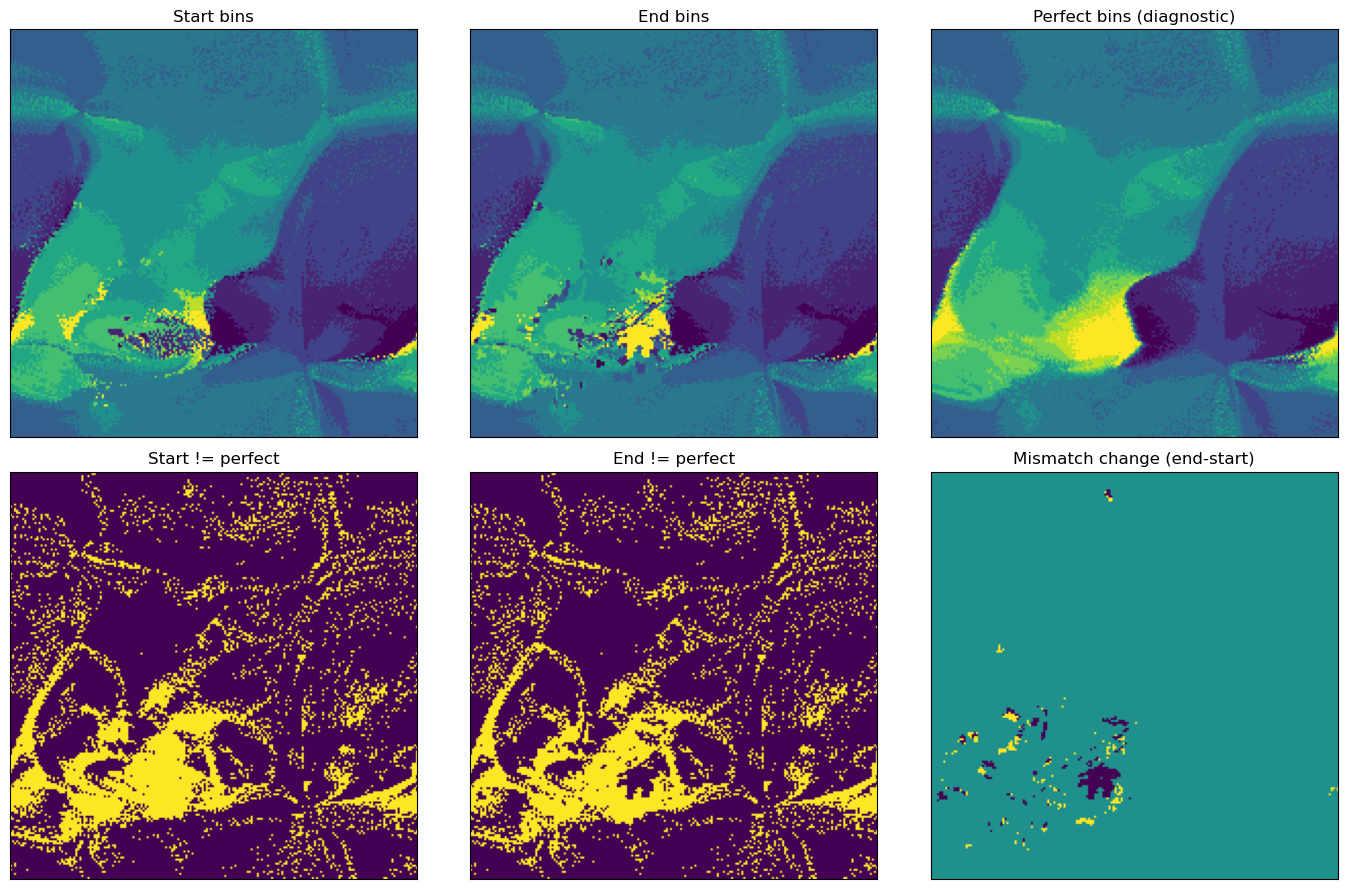

Match to perfect: start=0.795, end=0.799, Δ=+0.005


In [19]:
plot_bins_triptych(
    perfect_bins=perfect,
    end_bins=final_bins,
    start_bins=initial_node_bins.reshape(som.H, som.W)
)